<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">פרויקט 2: Wikimedia Streaming אל OpenSearch</h2>
<p dir="rtl" align="right">במחברת הזאת בונים צינור רציף: מקור אירועים ציבורי, שולח בפייתון, שרת Kafka, צרכן בפייתון ומנוע החיפוש OpenSearch. כל אירוע מתקדם בנפרד, והצרכן כותב את המסמך לפני שמירת מיקום ההמשך שלו.</p><p dir="rtl" align="right"><strong>אין מגבלה כוללת של מספר אירועים או זמן קליטה.</strong> תא ההרצה נשאר פעיל עד לחיצה על עצירה, סיום המקור או שגיאה מפורשת. אין לצפות ש־Run All יסתיים מעצמו.</p><p dir="rtl" align="right">סביבת העבודה: Cursor, uv ו־Python 3.13.12. מומלץ להשלים קודם את מחברת 01 עם עשרת האירועים הסינתטיים.</p>
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">המסלול של אירוע אחד</h2>
<p dir="rtl" align="right">Kafka שומר רשומות ומאפשר לצרכן להתקדם בקצב שלו. OpenSearch שומר מסמכים שאפשר לחפש ולסכם. התפקידים משלימים זה את זה.</p>
</div>
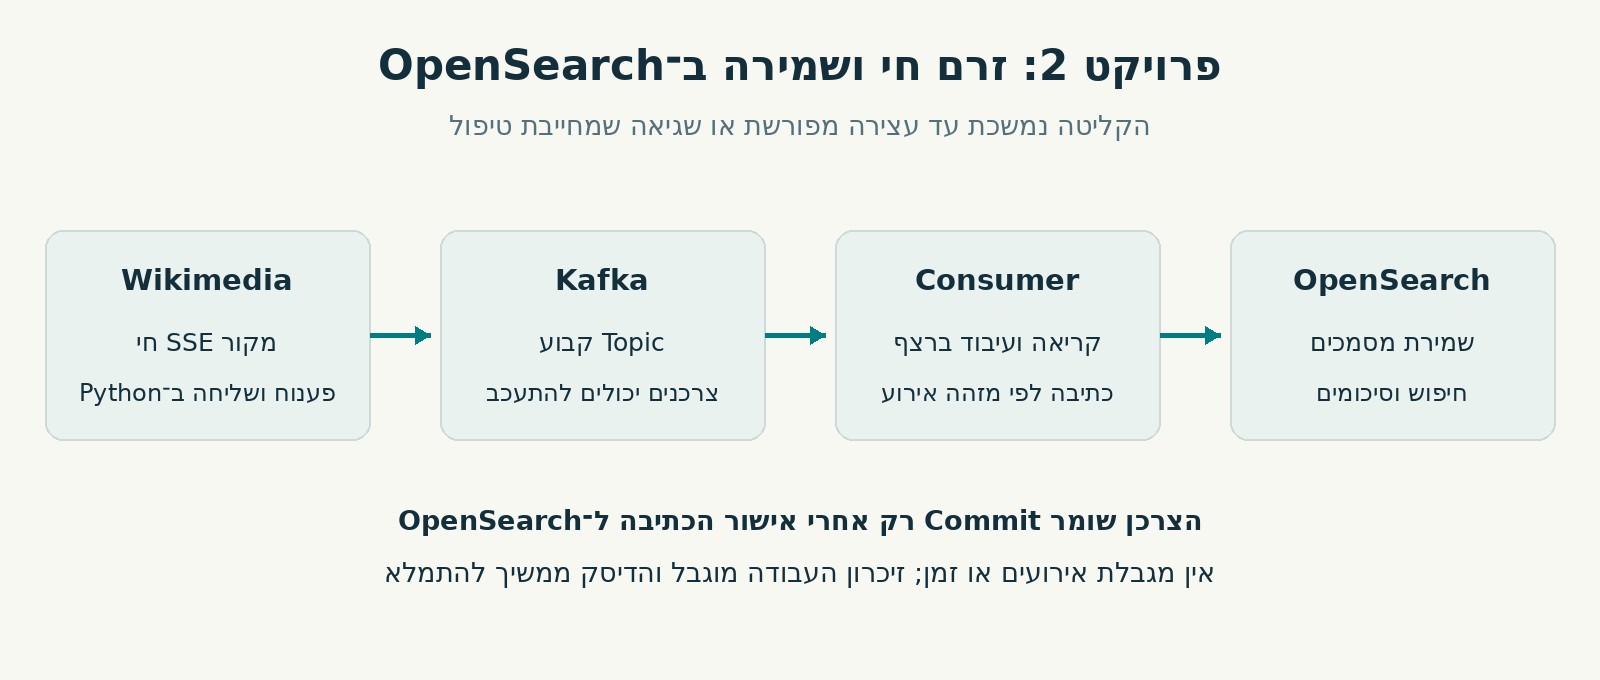


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">התקנה והפעלה לפני פתיחת המחברת</h2>
<p dir="rtl" align="right">פתחו את כל תיקיית הפרויקט ב־Cursor ובחרו Kernel מתוך .venv. פתחו Docker Desktop והמתינו להפעלת המנוע. במסוף הפרויקט הריצו:</p></div>

```powershell
uv sync --locked
uv run --locked python scripts/kafka_docker.py start
uv run --locked python scripts/check_kafka.py
uv run --locked python scripts/opensearch_docker.py start
```

<div dir="rtl" lang="he" align="right"><p dir="rtl" align="right">הכלי האחרון מוריד ומפעיל OpenSearch בגרסה קבועה. כתובת השרת המקומי היא <code dir="ltr">http://127.0.0.1:9200</code>. הנתונים נשמרים ב־Docker volume גם כאשר עוצרים את המכולה.</p><p dir="rtl" align="right">זו תצורת מעבדה מקומית, עם חיבור ל־localhost וללא אימות. היא אינה הגדרה לפרסום שרת ברשת. אם OpenSearch אינו עולה, ראו את סעיף הזיכרון ו־vm.max_map_count במדריך ההתקנה.</p>
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">1. הגדרות קבועות לפרויקט</h2>
<p dir="rtl" align="right">שמות Topic, קבוצת הצרכנים וה־Index נשארים קבועים בין הרצות. כך אפשר להמשיך מקריאת רשומות שכבר נשמרו ב־Kafka. אין צורך בדגלי RUN_LIVE של המחברת הישנה.</p><p dir="rtl" align="right"><code dir="ltr">None</code> בשתי מגבלות המקור מציין שאין תקרה כוללת. זמני ההמתנה של בקשות רשת ותורי העבודה עדיין מוגבלים.</p>
</div>

In [ ]:
import json
import os
import sys
import threading
from importlib.metadata import version

from scripts.wikimedia_stream import iter_wikimedia_events
from scripts.kafka_opensearch_streaming import (
    OpenSearchPipelineError,
    create_opensearch_client,
    prepare_pipeline,
    run_opensearch_pipeline,
)

BOOTSTRAP_SERVERS = "127.0.0.1:9092"
OPENSEARCH_URL = "http://127.0.0.1:9200"
TOPIC = "python.wikimedia.continuous.v1"
GROUP_ID = "python-wikimedia-opensearch-v1"
INDEX = "wikimedia-recentchanges-v1"
SERVER_NAME = None  # Optional client-side filter: "he.wikipedia.org"
MAX_EVENTS = None
MAX_SECONDS = None
PROGRESS_EVERY = 25

print("Python:", sys.version.split()[0])
print("Kernel:", sys.executable)
for package in ("confluent-kafka", "requests", "opensearch-py"):
    print(package, version(package))
if sys.version_info[:3] != (3, 13, 12):
    print("Select the project .venv Kernel for Python 3.13.12.")

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">2. בדיקת החיבורים והכנת יעד השמירה</h2>
<p dir="rtl" align="right">לפני שמתחברים לזרם החי, בודקים Kafka ו־OpenSearch. אם ה־Topic או ה־Index אינם קיימים, יוצרים אותם. אם כבר קיימת תצורה שאינה מתאימה, עוצרים עם שגיאה במקום לשנות נתונים קיימים.</p><p dir="rtl" align="right">במעבדה יש Broker אחד, שלוש מחיצות ועותק אחד ב־Kafka. ב־OpenSearch יש Shard אחד ללא Replica. אלה הגדרות לתרגול על מחשב אחד.</p>
</div>

In [ ]:
preflight = prepare_pipeline(
    topic=TOPIC,
    bootstrap_servers=BOOTSTRAP_SERVERS,
    opensearch_url=OPENSEARCH_URL,
    index=INDEX,
)
print(json.dumps(preflight, indent=2))

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">3. איזה מסמך נכתב ל־OpenSearch?</h2>
<table dir="rtl" width="100%"><tr><td dir="rtl" align="right" width="35%">שדה</td><td dir="rtl" align="right" width="65%">משמעות</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">event_id</code></td><td dir="rtl" align="right" width="65%">מזהה האירוע המקורי מתוך meta.id.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">event_time</code></td><td dir="rtl" align="right" width="65%">זמן האירוע מתוך meta.dt, שעליו מבוססים מיון וחלונות זמן.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">server_name</code></td><td dir="rtl" align="right" width="65%">האתר שממנו הגיע האירוע.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">bot</code></td><td dir="rtl" align="right" width="65%">הסימון המקורי של האירוע כבוט או כפעילות אחרת.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">title, type, wiki, namespace</code></td><td dir="rtl" align="right" width="65%">שדות תוכן נבחרים לצורך חיפוש וניתוח.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">kafka_topic, kafka_partition, kafka_offset</code></td><td dir="rtl" align="right" width="65%">המיקום שבו הצרכן קרא את הרשומה.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">indexed_at</code></td><td dir="rtl" align="right" width="65%">הזמן שבו היישום הכין את המסמך לכתיבה.</td></tr></table><p dir="rtl" align="right">ה־Index משתמש בסכמה מפורשת. מזהה המסמך הוא SHA-256 של event_id, ולכן כתיבה חוזרת של אותו אירוע מעדכנת את אותו מסמך. זה מאפשר התאוששות מכשל בין הכתיבה לבין Commit, אך אינו יוצר עסקה אחת בין שני השרתים.</p>
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">4. הפעלת הזרם הרציף</h2>
<p dir="rtl" align="right"><strong>התא הבא נשאר פעיל בכוונה.</strong> סימון ההרצה ב־Cursor יישאר פעיל בזמן הקליטה. עוצרים באמצעות כפתור העצירה של התא. בתהליך מסוף מקביל משתמשים ב־Ctrl+C. אין צורך לאתחל את ה־Kernel כדי לעצור.</p><p dir="rtl" align="right">ה־Producer פועל בזמן שה־Consumer כותב ל־OpenSearch בתהליכון נפרד. כל 25 כתיבות, וכן בעדכוני מצב תקופתיים, מודפס דוח קצר. הקוד אינו אוסף את הזרם לרשימת Python.</p><p dir="rtl" align="right">כאשר צרכן ממשיך לקרוא רשומות מהרצה קודמת, מספר הכתיבות עשוי להיות גדול ממספר האירועים שהשולח הנוכחי קלט. זה מצב תקין.</p>
</div>

In [ ]:
source_stats = {}
stop_event = threading.Event()
stream_report = None

def show_progress(report):
    keys = ("accepted", "confirmed", "consumed", "indexed", "committed",
            "committed_current_run", "consumed_other_runs")
    print("STREAM", {key: report.get(key) for key in keys}, flush=True)

events = iter_wikimedia_events(
    max_events=MAX_EVENTS,
    max_seconds=MAX_SECONDS,
    server_name=SERVER_NAME,
    stats=source_stats,
    stop_event=stop_event,
)
try:
    stream_report = run_opensearch_pipeline(
        events,
        topic=TOPIC,
        bootstrap_servers=BOOTSTRAP_SERVERS,
        opensearch_url=OPENSEARCH_URL,
        index=INDEX,
        group_id=GROUP_ID,
        stop_event=stop_event,
        on_progress=show_progress,
        progress_every=PROGRESS_EVERY,
        preflight=False,
    )
except OpenSearchPipelineError as exc:
    stream_report = exc.report
    print("Pipeline failed at stage:", exc.stage)
    raise
finally:
    stop_event.set()
    events.close()
    print("SOURCE", {key: source_stats.get(key) for key in
          ("received", "invalid", "filtered", "reconnects",
           "dedup_cache_size", "dedup_evictions", "stop_reason")})

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">5. פירוש דוח ההרצה</h2>
<table dir="rtl" width="100%"><tr><td dir="rtl" align="right" width="35%">מונה</td><td dir="rtl" align="right" width="65%">מה הוא אומר</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">accepted</code></td><td dir="rtl" align="right" width="65%">כמה רשומות נכנסו לתור השולח בהרצה הנוכחית.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">confirmed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות קיבלו אישור מסירה מ־Kafka.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">consumed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הצרכן קרא, כולל נתונים קודמים שממתינים ב־Topic.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">indexed</code></td><td dir="rtl" align="right" width="65%">כמה פעולות כתיבה ל־OpenSearch קיבלו אישור.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">committed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הושלמו ושמירת מיקום ההמשך שלהן אושרה.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">committed_current_run</code></td><td dir="rtl" align="right" width="65%">כמה רשומות שהשולח הנוכחי שלח הושלמו על ידי הצרכן.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">consumed_other_runs</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הגיעו מהרצות קודמות או משולחים אחרים.</td></tr></table><p dir="rtl" align="right">מספר פעולות Index אינו בהכרח מספר המסמכים הייחודיים. כתיבה חוזרת לאותו מזהה נספרת כפעולת כתיבה נוספת. גם מספר המסמכים ב־Index עשוי לכלול הרצות קודמות.</p><p dir="rtl" align="right">לאחר עצירה הריצו את תאי הבדיקה הבאים ידנית אם Cursor ביטל את המשך Run All. זמן הסגירה כולל המתנה מוגבלת לשליחות ולצרכן. נתונים שנשארו ב־Kafka יכולים להמתין להפעלה הבאה.</p>
</div>

In [ ]:
if stream_report is None:
    print("No final report yet. Start the stream cell, then stop it normally.")
else:
    print(json.dumps(stream_report, indent=2, default=str))

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">6. ספירת המסמכים והצגת הרשומות האחרונות</h2>
<p dir="rtl" align="right">כעת קוראים מ־OpenSearch, ולא מרשימה בזיכרון המחברת. פעולת Refresh מאפשרת לשאילתת החיפוש לראות גם כתיבות שהסתיימו לאחרונה. מבצעים אותה כאן לצורך ההדגמה, לא לאחר כל אירוע בזרם.</p><p dir="rtl" align="right">לבדיקה בזמן שתא הזרם רץ אפשר לפתוח בדפדפן את <code dir="ltr">http://127.0.0.1:9200/wikimedia-recentchanges-v1/_count</code>. תאי המחברת עצמה רצים באותו Kernel, ולכן מריצים אותם לאחר העצירה.</p>
</div>

In [ ]:
client = create_opensearch_client(OPENSEARCH_URL)
try:
    client.indices.refresh(index=INDEX)
    print("Documents in index:", client.count(index=INDEX)["count"])
    latest = client.search(index=INDEX, body={
        "size": 5,
        "sort": [{"event_time": {"order": "desc"}}],
        "_source": ["event_id", "event_time", "server_name", "bot", "title"],
        "query": {"match_all": {}},
    })
    for hit in latest["hits"]["hits"]:
        print(json.dumps(hit["_source"], ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">7. חיפוש לפי אתר</h2>
<p dir="rtl" align="right">שם האתר מוגדר כשדה keyword, ולכן משתמשים בשאילתת term על שם השדה עצמו. אם אין תוצאות, ייתכן שלא נקלטו אירועים מהאתר שבחרנו. אפשר לבחור אתר שהופיע בתא הקודם.</p>
</div>

In [ ]:
SEARCH_SITE = "he.wikipedia.org"
client = create_opensearch_client(OPENSEARCH_URL)
try:
    matches = client.search(index=INDEX, body={
        "size": 5,
        "query": {"term": {"server_name": SEARCH_SITE}},
        "sort": [{"event_time": {"order": "desc"}}],
        "_source": ["event_time", "server_name", "title", "bot"],
    })
    print("Matching documents:", matches["hits"]["total"])
    for hit in matches["hits"]["hits"]:
        print(json.dumps(hit["_source"], ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">8. סיכומים בתוך OpenSearch</h2>
<p dir="rtl" align="right">בפרויקט הראשון ספרנו עשרה מילונים בפייתון. כאן OpenSearch סופר את המסמכים שנשמרו: פעילות לפי אתר, בוטים ופעילות בכל דקה. אין צורך להוריד את כל המסמכים אל המחברת.</p><p dir="rtl" align="right">השאילתה מוגבלת לחמש עשרה הדקות האחרונות לפי זמן האירוע. סכומי Top 10 של אתרים אינם בהכרח כל האירועים. זו תמונת מצב של המסמכים הזמינים לחיפוש, ללא Watermark או סגירה סופית של חלונות.</p>
</div>

In [ ]:
client = create_opensearch_client(OPENSEARCH_URL)
try:
    summary = client.search(index=INDEX, body={
        "size": 0,
        "query": {"range": {"event_time": {"gte": "now-15m", "lte": "now"}}},
        "aggs": {
            "by_site": {"terms": {"field": "server_name", "size": 10}},
            "by_bot": {"terms": {"field": "bot"}},
            "per_minute": {"date_histogram": {
                "field": "event_time", "fixed_interval": "1m", "min_doc_count": 1}},
        },
    })
    print(json.dumps(summary["aggregations"], indent=2, ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">9. עצירה, המשך ושמירת נתונים</h2>
<p dir="rtl" align="right">אותה קבוצת צרכנים ממשיכה מהמיקום השמור ב־Kafka כל עוד הוא עדיין תקף. קבוצה חדשה עם earliest יכולה לקרוא מחדש את ההיסטוריה שעדיין נשמרת. מזהה מסמך קבוע מאפשר לעדכן את אותם מסמכים ב־OpenSearch במקום ליצור עותק נוסף לכל ניסיון.</p><p dir="rtl" align="right">סמן החיבור של Wikimedia נשמר בזיכרון במהלך אותה הרצה לצורך חידוש חיבור. אתחול ה־Kernel אינו משחזר אותו. אירועים שהתרחשו במקור כאשר היישום לא פעל אינם מובטחים בפרויקט הזה. רשומות שכבר הגיעו ל־Kafka הן עניין נפרד ויכולות להמתין לצרכן.</p><p dir="rtl" align="right">אין מגבלת אירועים בקוד, אך למחשב יש משאבים מוגבלים. זיכרון התורים ומטמון המזהים מוגבלים; נפח הדיסק של Kafka ו־OpenSearch עלול לגדול. זו מעבדת לימוד שמפעילים ועוצרים, ולא שירות ייצור ללא השגחה.</p></div>

```powershell
uv run --locked python scripts/opensearch_docker.py stop
uv run --locked python scripts/kafka_docker.py stop
```

<div dir="rtl" lang="he" align="right">
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">תרגילים לדיון וליישום</h2>
<ol dir="rtl" align="right"><li>הריצו את הזרם, עצרו ובדקו כמה מסמכים נכתבו. למה המונה indexed עשוי להיות שונה ממספר המסמכים?</li><li>בחרו אתר שמופיע בתוצאות ושאלו כמה מהאירועים בו מסומנים כבוטים.</li><li>הסבירו מה קורה אם OpenSearch הצליח לכתוב ואז התהליך נפל לפני Commit.</li><li>מה יקרה כאשר מתחילים עם אותה קבוצת צרכנים, ומה משתנה בקבוצה חדשה?</li><li>אילו שינויים נדרשים כדי לשמור את סמן Wikimedia גם אחרי אתחול?</li></ol>
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">מקורות וקובצי העזר</h2>
<ul dir="rtl" align="right"><li><a href="https://wikitech.wikimedia.org/wiki/Event_Platform/EventStreams">Wikimedia EventStreams</a></li><li><a href="https://docs.confluent.io/kafka-clients/python/current/overview.html">Confluent Python client</a></li><li><a href="https://docs.opensearch.org/latest/api-reference/document-apis/index-document/">OpenSearch Index Document API</a></li><li><a href="https://docs.opensearch.org/latest/install-and-configure/install-opensearch/docker/">OpenSearch Docker</a></li></ul><p dir="rtl" align="right">החיבור למקור נמצא בקובץ scripts/wikimedia_stream.py. התיאום בין השולח, הצרכן ויעד השמירה נמצא בקובץ scripts/kafka_opensearch_streaming.py. מדריך מלא נמצא ב־docs/NOTEBOOK_WALKTHROUGH_HE.md.</p>
</div>